<a href="https://colab.research.google.com/github/chenharry66/adversial-audio-experiments/blob/main/perturbation_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Setup

In [1]:
#install depencies
!pip install werpy scipy

In [2]:
# import dependncies
import werpy, torch

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from scipy.io import wavfile

rate, data = wavfile.read('/content/drive/MyDrive/FOLDER/01/recording2.wav')

data.dtype

dtype('int16')

In [5]:
clip = data[:160000]

In [6]:
import numpy as np

clip = clip / 32768

In [7]:
from IPython.display import Audio

audio = Audio(data = clip, rate = rate, normalize=False)
audio

##Model Definition and Establishing a Baseline

We now have our target audio. We will then initialize our frozen ASR model. Eventually after breaking whisper tiny, we can scale to more complex architectures.

In [8]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

processor = WhisperProcessor.from_pretrained("openai/whisper-tiny")
model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.75k [00:00<?, ?B/s]

In [9]:
input_features = processor(clip, sampling_rate=rate, return_tensors="pt")["input_features"]
predicted_ids = model.generate(input_features)

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


In [10]:
transcription = processor.batch_decode(predicted_ids, skip_special_tokens=False)

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


In [92]:
transcription =  "".join(transcription)

In [93]:
reference = "I must make an admission,” Ivan began. “I never could understand how it’s ‘possible to love one’s neighbors"

In [94]:
import regex as re

def custom_normalize(text):
    clean_text = re.sub(r'[\p{P}\p{S}]', '', text)
    return werpy.normalize(clean_text)

In [95]:
reference = custom_normalize(reference)
transcription = custom_normalize(transcription)

In [15]:
wer = werpy.wer(reference, transcription)
print(f"Baseline Wer: {wer * 100:.2f}%")

Baseline Wer: 33.33%


Our baseline WER measurement is 33%.



## Perturbial Optimization within Whole Audio Timeframe

We can think of perturbial generation as a naive constrained optimization problem, where we are optimizing against some differentiable loss function (in this case we define that loss funciton to be CTC loss) and our constraint is that the SNR for the clip has to be under some limit. From previous experiments,**we define that SNR to be 23dB initially.** We can think of our adverserial perturbation δ as essentially an array of weights where each weight **$w_t$ represents the amplitude of the waveform at time t.** For each iteration of training, we take our initial audio waveform $x$, add $\delta$ to it, and transcribe the result using our frozen model. And then we backpropogate, moving in direction of the loss function's gradient, taking a PGD like approach where we clip back to the boundrayr whenever the SNR exceeds our limit.

In [16]:
audio_rms = np.sqrt(np.mean(clip ** 2))

In [17]:
audio_rms

np.float64(0.0061113801398986626)

In [144]:
target_rms = np.float32(audio_rms/10**(23/20))

In [145]:
target_rms

np.float32(0.00043265257)

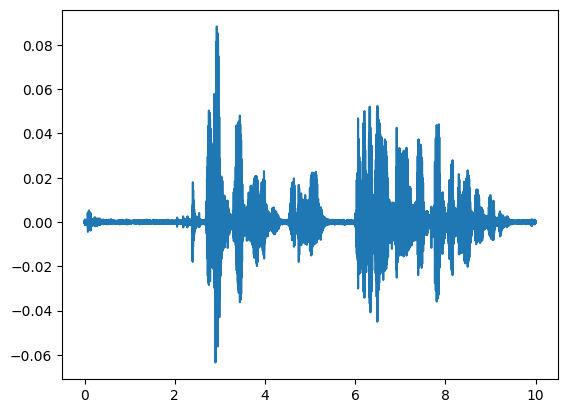

In [18]:
import matplotlib.pyplot as plt

t = np.linspace(0, 10, int(rate * 10), endpoint=False)
plt.plot(t, clip)

In [163]:
clip = torch.tensor(clip).float()
delta = torch.zeros_like(clip, requires_grad=True).float()

/tmp/ipykernel_1696/4144037484.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  clip = torch.tensor(clip).float()


In [164]:
clip

tensor([0.0005, 0.0007, 0.0006,  ..., 0.0003, 0.0002, 0.0003])

In [167]:
delta

tensor([0., 0., 0.,  ..., 0., 0., 0.], requires_grad=True)

In [168]:
from torch.nn import CTCLoss
 # pad the audio because expects 480,000 samples (30sec)
import torch.nn.functional as F

tgt = 480000


In [176]:
MAX_ITERS = 1000
ALPHA = 1e-5

# 1e-1 initalizaiton was terrible think it was just unlearning every single time, clipping couldnt sole it either

model.eval()

for p in model.parameters():
    p.requires_grad = False

labels = processor.tokenizer(reference, return_tensors="pt", return_attention_mask=False)['input_ids']

for i in range(MAX_ITERS):
    # forward pass
    delta.grad = None

    # uipdate needs to be here so you use the new elta
    perturbation = clip + delta
    perturbation = F.pad(perturbation, (0, max(0, tgt - perturbation.shape[-1])))

    mel_filters = torch.tensor(processor.feature_extractor.mel_filters, dtype=torch.float32)
    n_fft = processor.feature_extractor.n_fft
    hop_length = processor.feature_extractor.hop_length
    window = torch.hann_window(n_fft)
    stft = torch.stft(perturbation, n_fft, hop_length, window=window, return_complex=True)
    magnitudes = (stft[..., :-1].abs() ** 2).contiguous().float()
    mel_spec = mel_filters.T @ magnitudes
    log_spec = torch.clamp(mel_spec, min=1e-10).log10()
    log_spec = torch.maximum(log_spec, log_spec.max() - 8.0)
    log_spec = (log_spec + 4.0) / 4.0

    outputs = model(log_spec.unsqueeze(0), labels=labels, return_tensors="pt")
    # doesnt output a ctc matrix outputs a p
    loss = outputs.loss
    print(f"Loss for iteration {i}: {loss}")
    loss.backward()

    with torch.no_grad():
        delta += ALPHA * delta.grad

        current_rms = torch.sqrt(torch.mean(delta**2) + 1e-8)
        print(current_rms)

        if current_rms> target_rms:
            delta *= (target_rms/current_rms)

Loss for iteration 0: 5.663058280944824
0.00043321136
Loss for iteration 1: 7.1514892578125
0.00043294486
Loss for iteration 2: 7.978489398956299
0.00043278508
Loss for iteration 3: 8.476128578186035
0.0004327524
Loss for iteration 4: 8.810114860534668
0.0004327657
Loss for iteration 5: 9.14034366607666
0.00043278618
Loss for iteration 6: 9.610848426818848
0.0004327593
Loss for iteration 7: 9.942838668823242
0.00043274532
Loss for iteration 8: 10.200090408325195
0.00043276607
Loss for iteration 9: 10.41238784790039
0.00043277326
Loss for iteration 10: 10.501558303833008
0.00043280976
Loss for iteration 11: 10.670914649963379
0.0004327802
Loss for iteration 12: 10.913509368896484
0.00043282236
Loss for iteration 13: 11.120674133300781
0.00043289587
Loss for iteration 14: 11.300518035888672
0.00043287448
Loss for iteration 15: 11.50155258178711
0.00043294136
Loss for iteration 16: 11.853880882263184
0.00043283604
Loss for iteration 17: 12.140594482421875
0.00043288263
Loss for iteration 

We test our defined perturbations

In [178]:
#check to ensure we satisfy constraint
clip = clip.numpy()
delta = delta.detach().numpy()

In [181]:
20*np.log10(np.sqrt(np.mean(delta ** 2)) / np.sqrt(np.mean(clip ** 2)))

np.float32(-23.0)

In [182]:
aug_audio = clip + delta

In [193]:
input_features = processor(aug_audio, sampling_rate=rate, return_tensors="pt")["input_features"]
predicted_ids = model.generate(input_features)

transcription = processor.batch_decode(predicted_ids, skip_special_tokens=False)[0]

In [195]:
transcription

' The final statement copy of them, I will please understand cost and put a new pulling print'

In [196]:
transcription = custom_normalize(transcription)

In [198]:
wer = werpy.wer(reference, transcription)
print(f"Wer: {wer * 100:.2f}%")

Wer: 88.89%


This is what it sounds like

In [199]:
from IPython.display import Audio
audio = Audio(data = aug_audio, rate = rate, normalize=False)
audio

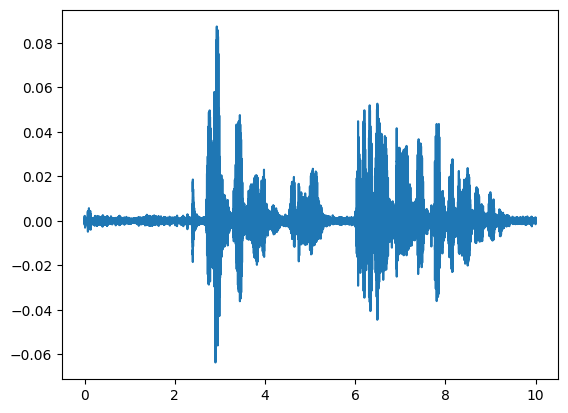

In [200]:
ts = np.linspace(0, 10, 10 * rate)
plt.plot(ts, aug_audio)
#check out the spectogram

Compare this to a randomly generated uniform noise fo the same rms.

In [211]:
rng = np.random.default_rng(seed=42)

noise = rng.uniform(low=-1.0, high=1.0, size=160000)
noise_rms = np.sqrt(np.mean(noise ** 2))
scaled_noise = noise * (target_rms / noise_rms)

In [212]:
aug2 = np.float32(scaled_noise) + clip

In [213]:
audio = Audio(data = (scaled_noise + clip), rate = rate, normalize=False)
audio

In [214]:
input_features = processor(aug2, sampling_rate=rate, return_tensors="pt")["input_features"]
predicted_ids = model.generate(input_features)
transcription = processor.batch_decode(predicted_ids, skip_special_tokens=False)[0]

In [215]:
transcription

" I must make an admission. I can begin. I never go understand how it's possible to law one's neighbors."

In [216]:
transcription = custom_normalize(transcription)

In [217]:
wer = werpy.wer(reference, transcription)
print(f"Wer: {wer * 100:.2f}%")

Wer: 27.78%


## Perturbial Optimization Within Windowed-Timeframes

## Psychoacoustic Perturbial Optimizations